In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

cwd = Path.cwd()
PROJECT_DIR = cwd if (cwd / "dataset").exists() else cwd.parent
DATA_PATH = PROJECT_DIR / "dataset" / "heart_failure_cleaned.csv"

df = pd.read_csv("C:\\Users\\vaibh\\OneDrive\\Desktop\\Heart_Failure_Survival_Analysis\\dataset\\heart_failure_clinical_records_dataset.csv")

print("EDA dataset loaded:", df.shape)


EDA dataset loaded: (299, 13)


In [3]:

display(df.describe().T)

print("\nData types:")
print(df.dtypes)

print("\nOutcome counts:")
print(df["DEATH_EVENT"].value_counts())


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0



Data types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

Outcome counts:
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


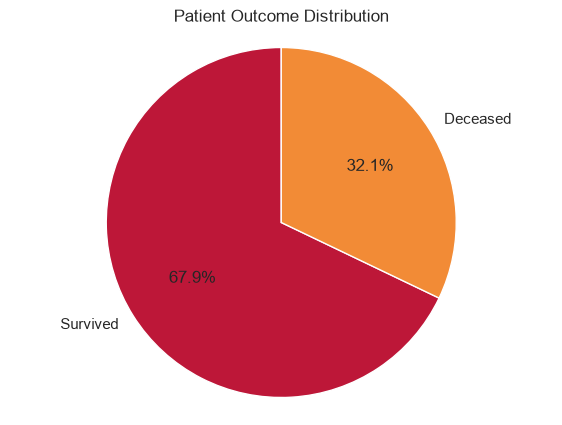

Survivors: 203
Deaths: 96
Mortality rate: 32.11 %


In [4]:

outcome_counts = df["DEATH_EVENT"].value_counts().sort_index()

labels = ["Survived", "Deceased"]
values = [
    outcome_counts.get(0, 0),
    outcome_counts.get(1, 0)
]

plt.figure(figsize=(7, 5))
plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#BD1738", "#F28B36"]
)
plt.title("Patient Outcome Distribution")
plt.axis("equal")
plt.show()

print("Survivors:", values[0])
print("Deaths:", values[1])
print("Mortality rate:", round(values[1] / len(df) * 100, 2), "%")


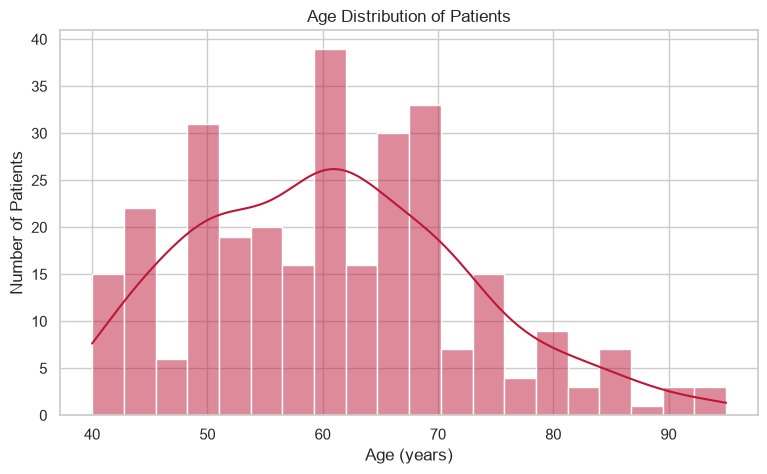

In [5]:

plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True,
    color="#BD1738"
)
plt.title("Age Distribution of Patients")
plt.xlabel("Age (years)")
plt.ylabel("Number of Patients")
plt.show()


In [7]:

df["Age_Group"] = pd.cut(
    df["age"],
    bins=[0, 50, 60, 70, float("inf")],
    labels=["≤50", "51–60", "61–70", "71+"],
    include_lowest=True
)

age_outcomes = (
    df.groupby(["Age_Group", "DEATH_EVENT"], observed=False)
    .size()
    .reset_index(name="Patients")
)

age_outcomes["Outcome"] = age_outcomes["DEATH_EVENT"].map({
    0: "Survived",
    1: "Deceased"
})

fig = px.bar(
    age_outcomes,
    x="Age_Group",
    y="Patients",
    color="Outcome",
    barmode="group",
    text_auto=True,
    color_discrete_map={
        "Survived": "#BD1738",
        "Deceased": "#F28B36"
    },
    title="Patient Outcomes by Age Group"
)

fig.show()

# Mortality proportion within each age group
age_mortality = (
    df.groupby("Age_Group", observed=False)["DEATH_EVENT"]
    .agg(["sum", "count"])
)
age_mortality["Mortality_Percentage"] = (
    age_mortality["sum"] / age_mortality["count"] * 100
)
display(age_mortality)


,sum,count,Mortality_Percentage
Age_Group,,,
≤50,19,74,25.675676
51–60,25,88,28.409091
61–70,21,85,24.705882
71+,31,52,59.615385


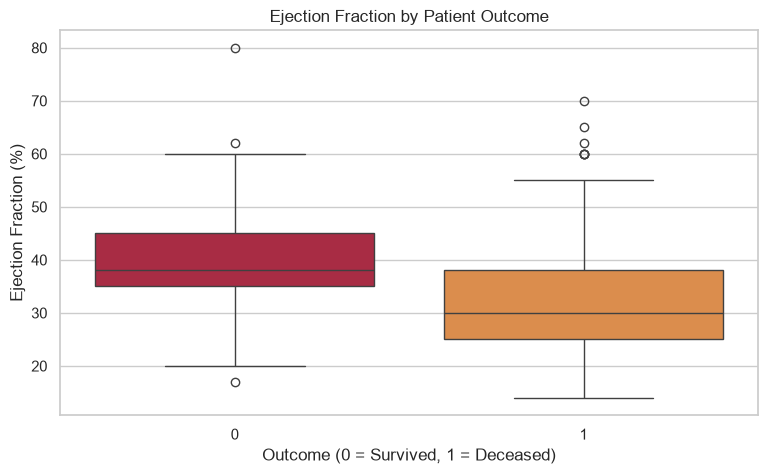

,mean,median,std,count
DEATH_EVENT,,,,
0,40.26601,38.0,10.859963,203
1,33.46875,30.0,12.525303,96


In [8]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="DEATH_EVENT",
    y="ejection_fraction",
    hue="DEATH_EVENT",
    palette=["#BD1738", "#F28B36"],
    legend=False
)

plt.title("Ejection Fraction by Patient Outcome")
plt.xlabel("Outcome (0 = Survived, 1 = Deceased)")
plt.ylabel("Ejection Fraction (%)")
plt.show()

display(
    df.groupby("DEATH_EVENT")["ejection_fraction"]
    .agg(["mean", "median", "std", "count"])
)


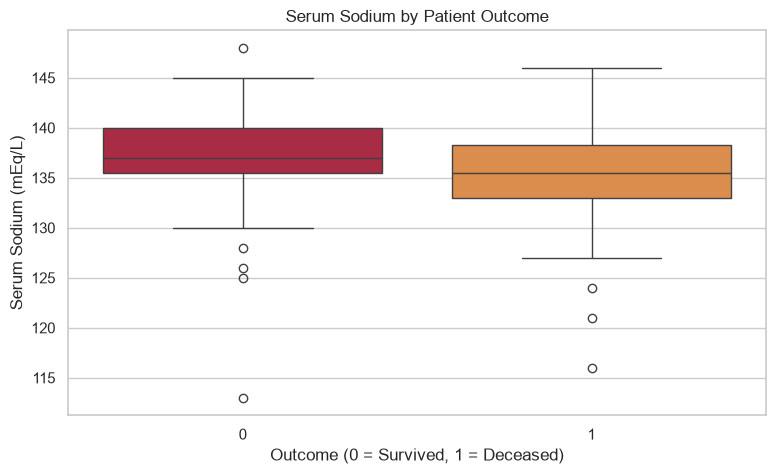

In [9]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="DEATH_EVENT",
    y="serum_sodium",
    hue="DEATH_EVENT",
    palette=["#BD1738", "#F28B36"],
    legend=False
)

plt.title("Serum Sodium by Patient Outcome")
plt.xlabel("Outcome (0 = Survived, 1 = Deceased)")
plt.ylabel("Serum Sodium (mEq/L)")
plt.show()


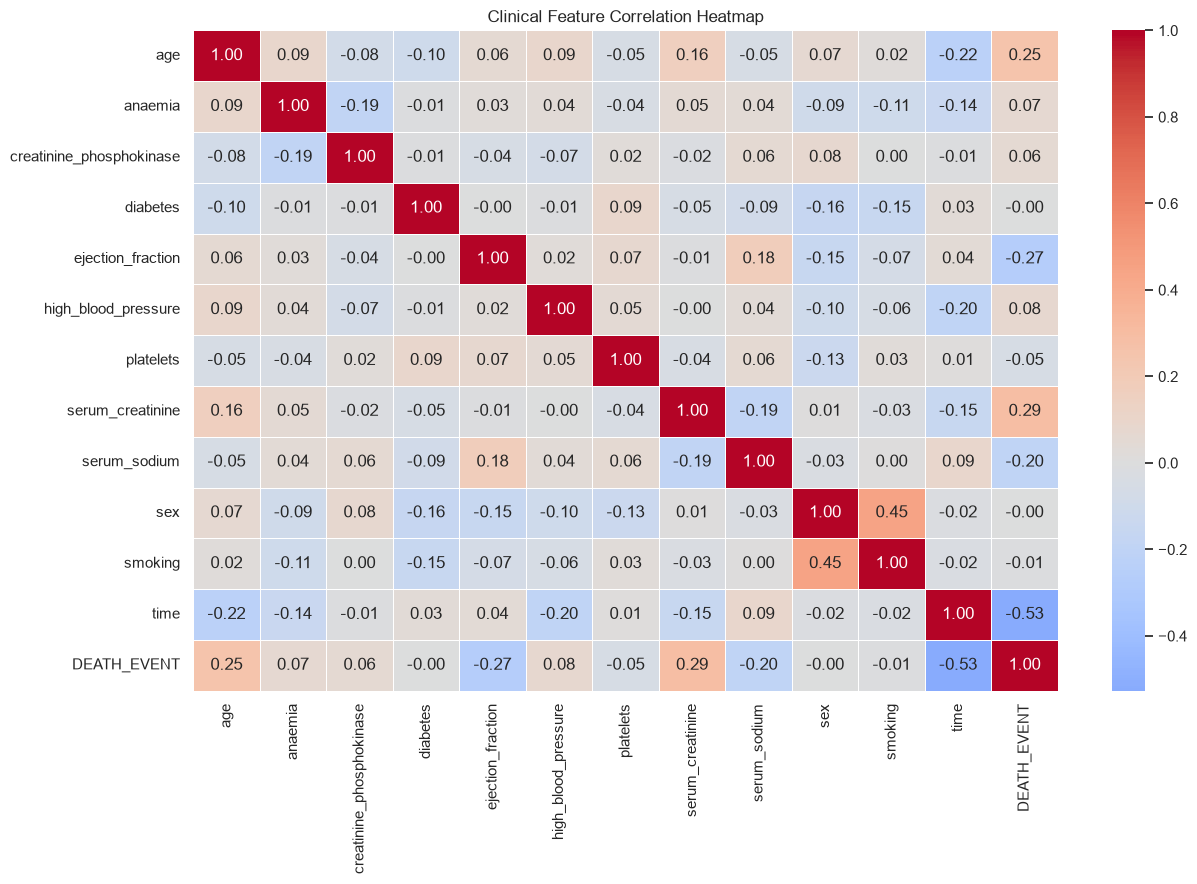

In [10]:

numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()

plt.figure(figsize=(13, 9))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Clinical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [11]:

clinical_features = [
    "anaemia", "diabetes",
    "high_blood_pressure", "sex", "smoking"
]

mortality_data = []

for feature in clinical_features:
    grouped = df.groupby(feature)["DEATH_EVENT"].agg(["sum", "count"])

    for group, row in grouped.iterrows():
        mortality_data.append({
            "Feature": feature,
            "Group": str(group),
            "Mortality (%)": row["sum"] / row["count"] * 100,
            "Patients": row["count"]
        })

mortality_df = pd.DataFrame(mortality_data)

fig = px.bar(
    mortality_df,
    x="Feature",
    y="Mortality (%)",
    color="Group",
    barmode="group",
    hover_data=["Patients"],
    title="Mortality Percentage by Clinical Features",
    color_discrete_sequence=["#BD1738", "#F28B36"]
)
fig.show()

display(mortality_df)


,Feature,Group,Mortality (%),Patients
0,anaemia,0,29.411765,170
1,anaemia,1,35.658915,129
2,diabetes,0,32.183908,174
3,diabetes,1,32.000000,125
4,high_blood_pressure,0,29.381443,194
5,high_blood_pressure,1,37.142857,105
6,sex,0,32.380952,105
7,sex,1,31.958763,194
8,smoking,0,32.512315,203
9,smoking,1,31.250000,96


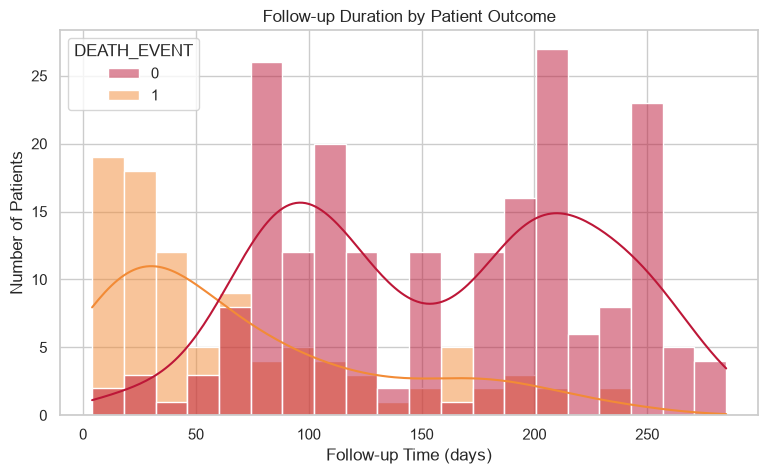

In [12]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="time",
    hue="DEATH_EVENT",
    bins=20,
    kde=True,
    palette=["#BD1738", "#F28B36"]
)

plt.title("Follow-up Duration by Patient Outcome")
plt.xlabel("Follow-up Time (days)")
plt.ylabel("Number of Patients")
plt.show()


In [13]:

OUTPUT_DIR = PROJECT_DIR / "visualizations"
OUTPUT_DIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="age", bins=20, kde=True, ax=ax)
ax.set_title("Age Distribution")
fig.savefig(OUTPUT_DIR / "age_distribution.png", dpi=300, bbox_inches="tight")
plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Clinical Correlation Heatmap")
fig.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.close(fig)

print("Visualizations saved to:", OUTPUT_DIR)


Visualizations saved to: c:\Users\vaibh\OneDrive\Desktop\Heart_Failure_Survival_Analysis\visualizations
